# AutoPilotRL — v2: tabular Q-learning

## Where we are
| Driver (v1) | Return | Crash rate | Mean speed |
|---|---|---|---|
| Random | 9.18 | 98% | 24.4 m/s |
| Always `IDLE` | 12.86 | 92% | 24.3 m/s |
| Rule-based | **22.83** | **2%** | 22.5 m/s |

The rule-based driver is safe but slow, and every one of its thresholds was chosen by hand. Now the car **learns** its own rules, from the reward alone.

## The idea of v2
1. Turn the observation into a **small number of discrete situations** $s$ ("car close ahead, left lane free, right lane blocked, …").
2. Keep a **table** $Q(s, a)$: the return the car expects if it takes action $a$ in situation $s$ and drives well afterwards.
3. Fill the table by **trial and error** with **Q-learning**, one of the founding algorithms of RL (Watkins, 1989).
4. Drive by choosing, in every situation, the action with the highest $Q$.

## What is new in v2
- Value functions and the **Bellman equation**.
- **Temporal-difference** learning: improving an estimate using another estimate.
- **Exploration vs exploitation**: ε-greedy, and optimistic initial values.
- **Termination vs truncation**: why a crash and the end of the time limit must be treated differently.
- The limits of tables, which motivate the neural networks of v3.

Training takes about 15–30 minutes on the CPU (the cell prints an estimate after 20 episodes).

In [1]:
# --- LIBRARIES ---

# Gymnasium: the standard interface for RL environments.
import gymnasium as gym

# Registers the highway-env environments.
import highway_env

# Numerical computing.
import numpy as np

# Plotting.
import matplotlib.pyplot as plt

# A colour map with one fixed colour per action.
from matplotlib.colors import ListedColormap

# Build GIF animations from frames.
from PIL import Image as PILImage

# Show images and GIFs in the notebook.
from IPython.display import Image, display

# File and folder paths.
from pathlib import Path

# Shared results file.
import json

# Measure time.
import time

# Folder for the videos.
VIDEO_DIR = Path("videos")

# Create it if needed.
VIDEO_DIR.mkdir(exist_ok=True)

# Folder for the results and the learned table.
RESULTS_DIR = Path("results")

# Create it if needed.
RESULTS_DIR.mkdir(exist_ok=True)

# Same environment as v1.
ENV_NAME = "highway-fast-v0"

# Action names, in index order.
ACTIONS = ["LANE_LEFT", "IDLE", "LANE_RIGHT", "FASTER", "SLOWER"]

# Action indices.
LEFT, IDLE, RIGHT, FASTER, SLOWER = 0, 1, 2, 3, 4

# Number of actions.
N_ACTIONS = len(ACTIONS)

## Step 1 — An observation made for a table

A table needs a **finite** number of states, so we must turn the continuous observation into a few discrete situations. To make that easy, the environment is configured to give a slightly different observation than v1:

| Setting | v1 | v2 | Why |
|---|---|---|---|
| `normalize` | True | **False** | thresholds in metres are easy to read |
| `vehicles_count` | 5 | **10** | see more of the traffic around |
| `see_behind` | False | **True** | see the cars **behind**, needed to change lane safely |

The traffic is the same: the same seed gives the same scenario as in v1, so the 50 test episodes are still comparable.

In [2]:
# --- ENVIRONMENT WITH A RAW OBSERVATION ---

# Observation: the ego and the 9 nearest vehicles (also behind), in metres and m/s.
OBS_CONFIG = {"observation": {"type": "Kinematics", "normalize": False, "vehicles_count": 10, "see_behind": True}}

# Environment for training and evaluation (no rendering).
env = gym.make(ENV_NAME, config=OBS_CONFIG)

# Same configuration with rendering, for the videos.
env_render = gym.make(ENV_NAME, render_mode="rgb_array", config=OBS_CONFIG)

# One observation, to check its shape.
obs, _ = env.reset(seed=0)

# 10 rows (vehicles) x 5 features (presence, x, y, vx, vy).
print("Observation shape:", obs.shape)

# The ego row: absolute position and speed.
print("Ego row:", np.round(obs[0], 2))

Observation shape: (10, 5)
Ego row: [  1.   150.82   8.    25.     0.  ]


## Step 2 — From observation to situation: the discretisation

The situation $s$ is a tuple of 7 small integers:

| Component | Values | Meaning |
|---|---|---|
| lane | 0, 1, 2 | which lane the car is in (left, middle, right) |
| speed | 0, 1, 2 | slow (≈20 m/s), medium (≈25), fast (≈30) |
| gap ahead, own lane | 0, 1, 2 | close (< 20 m), medium (20–50 m), far or no car |
| gap ahead, left lane | 0, 1, 2 | same, in the lane on the left |
| left lane occupied beside/behind | 0, 1 | a car within 15 m behind or beside us |
| gap ahead, right lane | 0, 1, 2 | same, in the lane on the right |
| right lane occupied beside/behind | 0, 1 | same, on the right |

The gap is the distance between the two cars' centres minus 5 m (one car length). A lane that does not exist (no left lane when we are in the leftmost one) counts as "close ahead" and "occupied", so changing into it looks bad.

Number of situations:

$$
|\mathcal{S}| = 3 \times 3 \times 3 \times (3 \times 2) \times (3 \times 2) = 972, \qquad |\mathcal{S}| \times |\mathcal{A}| = 4{,}860 \text{ values in the table}
$$

Choosing these features **is** a form of hand-written knowledge: we decided what matters (gaps, lanes, speed) and where the thresholds are. The difference from v1 is that we do not decide **what to do** in each situation: the agent learns that. In v3 a neural network will even learn **what to look at**.

In [3]:
# --- DISCRETISATION ---

# Width of a lane in metres (highway-env).
LANE_WIDTH = 4.0

# Length of a car in metres, subtracted from the centre-to-centre distance.
CAR_LENGTH = 5.0

# Number of lanes.
N_LANES = 3


# Bucket of a gap ahead: 0 = close (< 20 m), 1 = medium (20-50 m), 2 = far or no car.
def gap_bucket(gap):
    """Distance in metres -> 0, 1 or 2."""

    # Close.
    if gap < 20:

        # 0.
        return 0

    # Medium.
    if gap < 50:

        # 1.
        return 1

    # Far.
    return 2


# Observation (10 x 5, raw) -> situation (tuple of 7 integers).
def discretise(obs):
    """Return (lane, speed, gap_own, gap_left, busy_left, gap_right, busy_right)."""

    # Ego row: absolute lateral position and longitudinal speed.
    ego_y, ego_vx = obs[0, 2], obs[0, 3]

    # Lane index from the lateral position (lanes are 4 m apart, the leftmost at y = 0).
    lane = int(np.clip(round(ego_y / LANE_WIDTH), 0, N_LANES - 1))

    # Speed bucket: nearest of 20, 25, 30 m/s.
    speed = int(np.clip(round((ego_vx - 20) / 5), 0, 2))

    # Smallest gap ahead in each relative lane (-1 = left, 0 = own, +1 = right).
    gap_ahead = {-1: np.inf, 0: np.inf, 1: np.inf}

    # Is there a car beside or just behind, in each relative lane?
    busy = {-1: False, 0: False, 1: False}

    # Other vehicles (rows 1-9), only those present.
    for presence, dx, dy, dvx, dvy in obs[1:]:

        # Empty row.
        if presence < 0.5:

            # Skip it.
            continue

        # Relative lane of that vehicle.
        offset = int(round(dy / LANE_WIDTH))

        # Only the lanes next to us matter.
        if offset not in gap_ahead:

            # Skip it.
            continue

        # Ahead of us: update the smallest gap.
        if dx > 0:

            # Bumper-to-bumper distance.
            gap_ahead[offset] = min(gap_ahead[offset], dx - CAR_LENGTH)

        # Beside us or within 15 m behind: the lane is not safe to enter.
        if -15 < dx <= CAR_LENGTH:

            # Occupied.
            busy[offset] = True

    # Components for the side lanes.
    sides = []

    # Left (-1) and right (+1).
    for offset in (-1, 1):

        # The lane exists.
        if 0 <= lane + offset < N_LANES:

            # Its gap bucket and occupancy.
            sides += [gap_bucket(gap_ahead[offset]), int(busy[offset])]

        # The lane does not exist: looks blocked.
        else:

            # Close ahead and occupied.
            sides += [0, 1]

    # The situation.
    return (lane, speed, gap_bucket(gap_ahead[0]), *sides)


# Shape of the table: one axis per component, plus one for the actions.
Q_SHAPE = (3, 3, 3, 3, 2, 3, 2, N_ACTIONS)

# Number of situations.
N_STATES = int(np.prod(Q_SHAPE[:-1]))

# Report.
print(f"{N_STATES} situations x {N_ACTIONS} actions = {N_STATES * N_ACTIONS} values in the table")

# Example: the situation at the start of an episode.
print("Situation at the start of scenario 0:", discretise(obs))

972 situations x 5 actions = 4860 values in the table
Situation at the start of scenario 0: (2, 1, 2, 0, 0, 0, 1)


## Step 3 — Q-learning

### Action values
The **action value** of a policy $\pi$ is the expected return when taking action $a$ in state $s$ and following $\pi$ afterwards:

$$
Q^{\pi}(s, a) = \mathbb{E}_{\pi}\big[\, G_t \mid s_t = s,\ a_t = a \,\big]
$$

The **optimal** action values $Q^*$ satisfy the **Bellman optimality equation**: the value of an action is the immediate reward plus the discounted value of the best action in the next state,

$$
Q^*(s, a) = \mathbb{E}\Big[\, r_{t+1} + \gamma \max_{a'} Q^*(s_{t+1}, a') \;\Big|\; s_t = s,\ a_t = a \Big]
$$

Once $Q^*$ is known, driving optimally is trivial: $\pi^*(s) = \arg\max_a Q^*(s, a)$.

### The update
We do not know $P$ (the traffic simulator is a black box), so we cannot compute the expectation. Q-learning replaces it with the **one transition actually observed** $(s, a, r, s')$ and moves the table a little towards it:

$$
\underbrace{Q(s, a)}_{\text{old estimate}} \leftarrow Q(s, a) + \alpha \Big[\, \underbrace{r + \gamma \max_{a'} Q(s', a')}_{\text{TD target}} - Q(s, a) \Big]
$$

The term in brackets is the **temporal-difference (TD) error**: how surprised the agent is. The target itself uses the table (an estimate built from another estimate, called **bootstrapping**), yet under mild conditions Q-learning converges to $Q^*$.

| Hyperparameter | Value | Meaning |
|---|---|---|
| $\alpha$ | 0.1 | learning rate: how far each update moves the table |
| $\gamma$ | 0.95 | discount: a reward 20 s ahead still weighs $0.95^{20} \approx 0.36$ |

### Termination vs truncation
- After a **crash** (`terminated`) there is no future: the target is just $r$.
- When the **30 s time limit** ends the episode (`truncated`), the car is still driving and the future still exists: the target keeps $\gamma \max_{a'} Q(s', a')$.

$$
\text{target} = r + \gamma\, (1 - \text{terminated}) \max_{a'} Q(s', a')
$$

Treating the time limit like a crash would teach the agent that driving well at second 29 is worthless, because "the world ends". It is a classic bug in RL code.

### Exploration: ε-greedy and optimism
If the agent always picks the best action according to its current table, it never discovers actions it has not tried. Two remedies:
- **ε-greedy**: with probability $\varepsilon$ a random action, otherwise the best one. $\varepsilon$ decays linearly from 1 (all exploration) to 0.05 over the first 70% of training.
- **Optimistic initial values**: the table starts at $Q = 10$, more than most real returns (with rewards near 0.8 and $\gamma = 0.95$, a long safe drive is worth about 13 at the start of an episode and less later). Every untried action looks attractive until it has been tried and its value has dropped.

### Training
2,000 episodes on training scenarios (seeds from 10,000), never on the 50 test scenarios. During training we record the return, the crashes and the share of situations visited.

In [4]:
# --- Q-LEARNING ---

# Training episodes.
EPISODES = 2000

# Learning rate.
ALPHA = 0.1

# Discount factor.
GAMMA = 0.95

# Initial and final exploration rate.
EPS_START, EPS_END = 1.0, 0.05

# Fraction of training over which epsilon decays.
EPS_DECAY_FRACTION = 0.7

# Optimistic initial value of every entry of the table.
Q_INIT = 10.0

# The table, filled with the optimistic value.
Q = np.full(Q_SHAPE, Q_INIT)

# How many times each (situation, action) has been updated.
visits = np.zeros(Q_SHAPE, dtype=np.int64)

# Random generator for the exploration (fixed seed: reproducible).
rng = np.random.default_rng(0)


# Exploration rate for a given episode.
def epsilon(episode):
    """Linear decay from EPS_START to EPS_END, then constant."""

    # Fraction of the decay completed.
    fraction = min(1.0, episode / (EPS_DECAY_FRACTION * EPISODES))

    # Linear interpolation.
    return EPS_START + fraction * (EPS_END - EPS_START)


# History for the plots.
history = {"return": [], "crash": [], "visited": []}

# Start time.
start = time.perf_counter()

# Training loop.
for episode in range(EPISODES):

    # A training scenario (seeds 10,000 and above, never the test seeds).
    obs, info = env.reset(seed=10_000 + episode)

    # Current situation.
    s = discretise(obs)

    # Exploration rate of this episode.
    eps = epsilon(episode)

    # Return of the episode.
    episode_return = 0.0

    # Until the episode ends.
    done = False

    # Play and learn.
    while not done:

        # epsilon-greedy: random action with probability eps, otherwise the best one in the table.
        a = int(rng.integers(N_ACTIONS)) if rng.random() < eps else int(np.argmax(Q[s]))

        # One step in the environment.
        obs, r, terminated, truncated, info = env.step(a)

        # Next situation.
        s_next = discretise(obs)

        # TD target: no future after a crash, the future still counts after the time limit.
        target = r + GAMMA * (0.0 if terminated else np.max(Q[s_next]))

        # Move the table towards the target (s + (a,) indexes one entry of the table).
        Q[s + (a,)] += ALPHA * (target - Q[s + (a,)])

        # Count the update.
        visits[s + (a,)] += 1

        # Accumulate the reward.
        episode_return += r

        # Move on.
        s = s_next

        # Crash or time limit.
        done = terminated or truncated

    # Store the return.
    history["return"].append(episode_return)

    # Store the crash.
    history["crash"].append(info["crashed"])

    # Share of situations where at least one action has been tried.
    history["visited"].append((visits.sum(axis=-1) > 0).mean())

    # Early time estimate.
    if episode == 19:

        # Seconds per episode so far.
        per_episode = (time.perf_counter() - start) / 20

        # Projected total.
        print(f"{per_episode:.2f} s/episode -> about {per_episode * EPISODES / 60:.0f} minutes for {EPISODES} episodes")

    # Progress every 200 episodes.
    if (episode + 1) % 200 == 0:

        # Averages over the last 200 episodes.
        print(f"episode {episode + 1:5d} | eps {eps:.2f} | return {np.mean(history['return'][-200:]):5.2f} | "
              f"crash rate {np.mean(history['crash'][-200:]):5.1%} | situations visited {history['visited'][-1]:5.1%} | "
              f"{time.perf_counter() - start:.0f}s")

# Save the learned table.
np.save(RESULTS_DIR / "v2_q_table.npy", Q)

0.21 s/episode -> about 7 minutes for 2000 episodes
episode   200 | eps 0.86 | return  9.07 | crash rate 94.5% | situations visited 28.5% | 35s
episode   400 | eps 0.73 | return  8.38 | crash rate 98.5% | situations visited 32.9% | 64s
episode   600 | eps 0.59 | return  9.49 | crash rate 95.0% | situations visited 35.4% | 96s
episode   800 | eps 0.46 | return 10.58 | crash rate 92.5% | situations visited 37.6% | 132s
episode  1000 | eps 0.32 | return 14.63 | crash rate 76.5% | situations visited 38.9% | 182s
episode  1200 | eps 0.19 | return 16.73 | crash rate 61.5% | situations visited 39.7% | 238s
episode  1400 | eps 0.05 | return 18.16 | crash rate 43.5% | situations visited 40.5% | 300s
episode  1600 | eps 0.05 | return 19.69 | crash rate 31.0% | situations visited 40.8% | 366s
episode  1800 | eps 0.05 | return 20.03 | crash rate 31.0% | situations visited 41.6% | 435s
episode  2000 | eps 0.05 | return 20.21 | crash rate 29.5% | situations visited 41.8% | 508s


## Step 4 — Learning curves

- **Return** and **crash rate** per episode, averaged over windows of 100 episodes. At the start $\varepsilon \approx 1$: the agent drives almost at random, so the curves start near the random driver of v1. As $\varepsilon$ decreases, they show what the table has learned, still mixed with some exploration.
- **ε** over the episodes.
- **Situations visited**: how much of the 972-situation table the agent has actually seen. Many combinations never happen in traffic (for example, three lanes all blocked at close range), so it will not reach 100%.

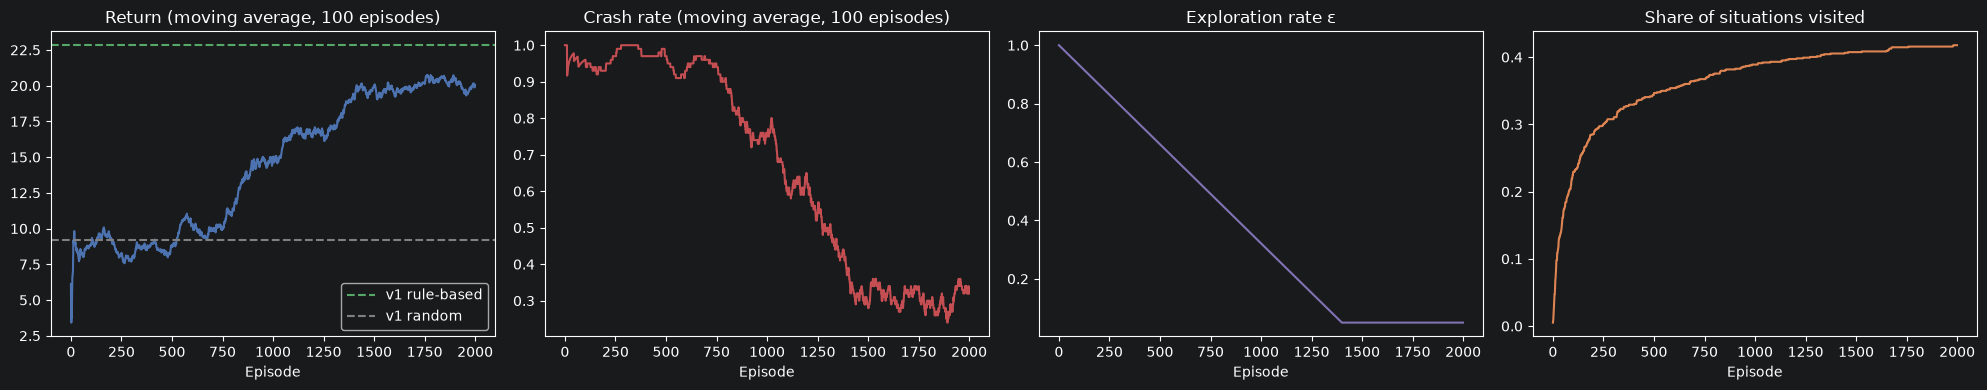

In [5]:
# --- LEARNING CURVES ---

# Moving average over a window.
def moving_average(x, window=100):
    """Average of the last `window` values at every point (shorter at the start)."""

    # As floats.
    x = np.asarray(x, dtype=float)

    # Cumulative sum with a leading zero.
    c = np.concatenate([[0.0], np.cumsum(x)])

    # Start index of each window.
    starts = np.maximum(0, np.arange(1, len(x) + 1) - window)

    # Window sums divided by window lengths.
    return (c[1:] - c[starts]) / (np.arange(1, len(x) + 1) - starts)


# Four panels.
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

# Return.
axes[0].plot(moving_average(history["return"]), color="#4C72B0")

# Rule-based reference.
axes[0].axhline(22.83, linestyle="--", color="#55A868", label="v1 rule-based")

# Random reference.
axes[0].axhline(9.18, linestyle="--", color="gray", label="v1 random")

# Title.
axes[0].set_title("Return (moving average, 100 episodes)")

# Legend.
axes[0].legend()

# Crash rate.
axes[1].plot(moving_average(history["crash"]), color="#C44E52")

# Title.
axes[1].set_title("Crash rate (moving average, 100 episodes)")

# Epsilon schedule.
axes[2].plot([epsilon(e) for e in range(EPISODES)], color="#8172B3")

# Title.
axes[2].set_title("Exploration rate ε")

# Situations visited.
axes[3].plot(history["visited"], color="#DD8452")

# Title.
axes[3].set_title("Share of situations visited")

# Common x label.
for ax in axes:

    # Episodes.
    ax.set_xlabel("Episode")

# Layout.
plt.tight_layout()

# Render.
plt.show()

## Step 5 — The learned driver on the 50 test scenarios

The learned policy is **greedy**: no exploration, always the action with the highest value,

$$
\pi(s) = \arg\max_a Q(s, a)
$$

It is evaluated on exactly the same 50 scenarios as the v1 drivers, with the same functions.

In [6]:
# --- EVALUATION ---

# The 50 fixed test scenarios (also used by the next versions).
EVAL_SEEDS = list(range(1000, 1050))


# Run a policy on the test scenarios and measure it.
def evaluate(policy, seeds=EVAL_SEEDS, env=env):
    """policy(env, obs) -> action. Returns a dict of per-episode arrays."""

    # Per-episode measurements.
    returns, crashes, speeds, distances, lengths = [], [], [], [], []

    # One episode per seed.
    for seed in seeds:

        # Start the episode.
        obs, info = env.reset(seed=seed)

        # Starting position of the ego car (x, along the road).
        x_start = env.unwrapped.vehicle.position[0]

        # Return, speeds and number of steps of this episode.
        episode_return, episode_speeds, steps = 0.0, [], 0

        # Until the episode ends.
        done = False

        # Play.
        while not done:

            # The policy chooses an action.
            action = policy(env, obs)

            # One step in the environment.
            obs, reward, terminated, truncated, info = env.step(action)

            # Accumulate the reward.
            episode_return += reward

            # Record the speed.
            episode_speeds.append(info["speed"])

            # One more decision.
            steps += 1

            # Crash or time limit.
            done = terminated or truncated

        # Store the measurements of this episode.
        returns.append(episode_return)

        # Crashed or not.
        crashes.append(info["crashed"])

        # Average speed.
        speeds.append(np.mean(episode_speeds))

        # Distance travelled.
        distances.append(env.unwrapped.vehicle.position[0] - x_start)

        # Number of decisions.
        lengths.append(steps)

    # Everything as NumPy arrays.
    return {"return": np.array(returns), "crash": np.array(crashes, dtype=float), "speed": np.array(speeds),
            "distance": np.array(distances), "length": np.array(lengths)}


# One line summary of an evaluation.
def summary(name, res):
    """Print the mean of every metric."""

    # Means.
    print(f"{name:<16} return {res['return'].mean():5.2f} | crash rate {res['crash'].mean():5.1%} | "
          f"speed {res['speed'].mean():5.2f} m/s | distance {res['distance'].mean():6.1f} m | length {res['length'].mean():5.2f}")


# --- VIDEOS ---

# Collects the intermediate frames that highway-env renders while an action is being executed.
class FrameRecorder:
    """highway-env calls _capture_frame() at every physics step once it is registered as the 'video wrapper'."""

    # Empty list of frames.
    def __init__(self, env):

        # The environment to render.
        self.env = env

        # Frames collected so far.
        self.frames = []

        # Frame rate (highway-env sets it: twice the simulation frequency, i.e. twice real time).
        self.frames_per_sec = 10

    # Called by highway-env at every intermediate physics step.
    def _capture_frame(self):

        # Render the current image and keep it.
        self.frames.append(self.env.render())


# Play one episode with rendering and save it as a GIF.
def record_episode(policy, seed, filename, env=env_render):
    """Return (path of the GIF, return of the episode, crashed)."""

    # Start the episode.
    obs, info = env.reset(seed=seed)

    # A new recorder for this episode.
    recorder = FrameRecorder(env)

    # First frame (this also creates the viewer, needed for the intermediate frames).
    recorder.frames.append(env.render())

    # Register the recorder, so that highway-env sends it the intermediate frames.
    env.unwrapped.set_record_video_wrapper(recorder)

    # Return of the episode.
    episode_return = 0.0

    # Until the episode ends.
    done = False

    # Play.
    while not done:

        # One decision.
        obs, reward, terminated, truncated, info = env.step(policy(env, obs))

        # Accumulate the reward.
        episode_return += reward

        # Last frame of the step (this also re-enables the intermediate frames for the next step).
        recorder.frames.append(env.render())

        # Crash or time limit.
        done = terminated or truncated

    # Path of the GIF.
    path = VIDEO_DIR / filename

    # Frames as PIL images.
    images = [PILImage.fromarray(f) for f in recorder.frames]

    # Save as an animated GIF: duration of each frame in milliseconds, loop forever.
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 / recorder.frames_per_sec), loop=0)

    # Path, return and crash.
    return path, episode_return, info["crashed"]


# Record an episode and show it in the notebook.
def show_episode(policy, seed, filename, title, env=env_render):
    """Save the GIF, print the outcome and display the animation."""

    # Record it.
    path, episode_return, crashed = record_episode(policy, seed, filename, env=env)

    # Outcome.
    print(f"{title}: return {episode_return:.2f}, {'CRASH' if crashed else 'no crash'}  ({path})")

    # The animation.
    display(Image(filename=str(path)))

Q-learning       return 23.05 | crash rate  8.0% | speed 23.05 m/s | distance  673.7 m | length 29.24
v1 random        return  8.37 | crash rate 96.0% | speed 23.46 m/s | distance  266.2 m | length 11.34
v1 always IDLE   return 12.86 | crash rate 92.0% | speed 24.28 m/s | distance  401.6 m | length 16.20
v1 rule-based    return 22.83 | crash rate  2.0% | speed 22.55 m/s | distance  670.4 m | length 29.66

Actions chosen on the test scenarios: LANE_LEFT 22%, IDLE 17%, LANE_RIGHT 17%, FASTER 11%, SLOWER 32%
Q-learning driver, scenario 1000: return 18.49, CRASH  (videos/v2_qlearning.gif)


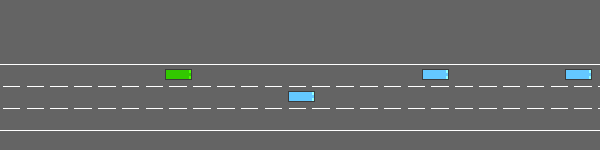

In [7]:
# --- EVALUATION OF THE LEARNED DRIVER ---

# Greedy policy from the table.
def q_policy(env, obs):
    """Best action in the table for the current situation."""

    # Highest value.
    return int(np.argmax(Q[discretise(obs)]))


# Evaluate on the 50 test scenarios.
res_q = evaluate(q_policy)

# Report.
summary("Q-learning", res_q)

# Results of v1 from the shared file.
RESULTS_PATH = RESULTS_DIR / "autopilot_results.json"

# Load them.
results_all = json.loads(RESULTS_PATH.read_text())

# Compare with the v1 drivers.
for name in ["v1 random", "v1 always IDLE", "v1 rule-based"]:

    # Saved means.
    r = results_all[name]

    # Same format as summary().
    print(f"{name:<16} return {r['return']:5.2f} | crash rate {r['crash']:5.1%} | speed {r['speed']:5.2f} m/s | "
          f"distance {r['distance']:6.1f} m | length {r['length']:5.2f}")

# How often each action is chosen on the test scenarios.
action_counts = np.zeros(N_ACTIONS, dtype=int)

# Replay the test scenarios and count the actions.
for seed in EVAL_SEEDS:

    # Start.
    obs, _ = env.reset(seed=seed)

    # Until the end.
    done = False

    # Play.
    while not done:

        # Greedy action.
        a = q_policy(env, obs)

        # Count it.
        action_counts[a] += 1

        # Step.
        obs, _, terminated, truncated, _ = env.step(a)

        # End?
        done = terminated or truncated

# Report the shares.
print("\nActions chosen on the test scenarios:", ", ".join(f"{ACTIONS[i]} {c / action_counts.sum():.0%}" for i, c in enumerate(action_counts)))

# The learned driver on the same scenario as the v1 videos.
show_episode(q_policy, seed=1000, filename="v2_qlearning.gif", title="Q-learning driver, scenario 1000", env=env_render)

## Step 6 — What did the table learn?

A table can be **read**: for every situation we can look at the chosen action. The heatmap shows the greedy action for the car in the **middle lane** at **medium speed**, for every combination of:
- rows: gap ahead in the own lane (close, medium, far);
- columns: state of the left and right lanes, as (gap ahead, occupied beside/behind).

To keep it readable we show only the columns where both side lanes are either "free" (far ahead, nobody beside) or "blocked" (close ahead or occupied). Cells marked with `·` are situations never visited during training: there the table still holds its initial value, and the "chosen" action is meaningless.

**What a sensible driver would do:** with a close car ahead and a free side lane, change lane; with everything blocked, slow down; with a free road, speed up or keep right.

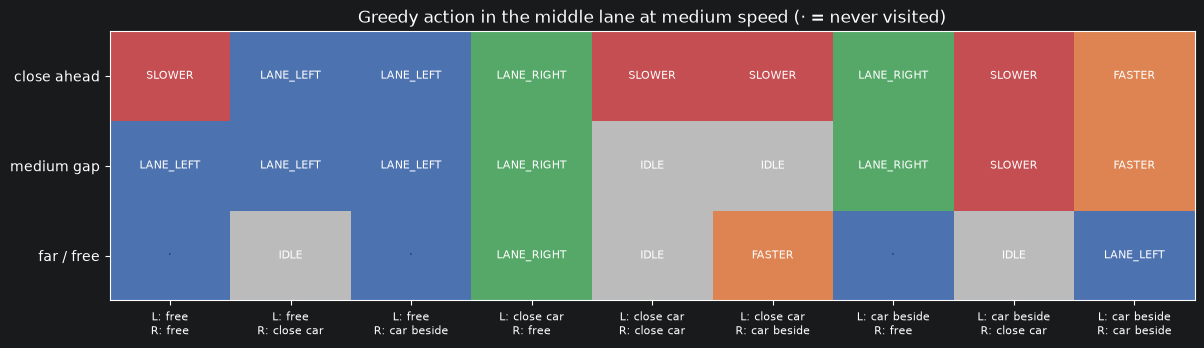

In [8]:
# --- READ THE TABLE ---

# Middle lane, medium speed.
LANE, SPEED = 1, 1

# Side-lane states: (gap bucket, occupied) -> short label.
SIDE_STATES = {(2, 0): "free", (0, 0): "close car", (2, 1): "car beside"}

# Columns: every combination of left and right side states.
columns = [(l, r) for l in SIDE_STATES for r in SIDE_STATES]

# Matrix of chosen actions (rows: own gap; columns: side combinations).
chosen = np.zeros((3, len(columns)), dtype=int)

# Matrix of visit counts.
seen = np.zeros((3, len(columns)), dtype=int)

# Fill both.
for gap_own in range(3):

    # Every column.
    for j, (left, right) in enumerate(columns):

        # The situation.
        s = (LANE, SPEED, gap_own, *left, *right)

        # Greedy action.
        chosen[gap_own, j] = int(np.argmax(Q[s]))

        # Total visits of this situation.
        seen[gap_own, j] = visits[s].sum()

# One panel.
fig, ax = plt.subplots(figsize=(14, 3.5))

# Colour per action (ListedColormap: one fixed colour per integer value).
cmap = ListedColormap(["#4C72B0", "#BBBBBB", "#55A868", "#DD8452", "#C44E52"])

# Heatmap of the actions.
ax.imshow(chosen, cmap=cmap, vmin=-0.5, vmax=N_ACTIONS - 0.5, aspect="auto")

# Write the action name (or a dot if never visited) in each cell.
for i in range(3):

    # Every column.
    for j in range(len(columns)):

        # Name or dot.
        text = ACTIONS[chosen[i, j]] if seen[i, j] > 0 else "·"

        # Write it.
        ax.text(j, i, text, ha="center", va="center", fontsize=8, color="white" if seen[i, j] > 0 else "black")

# Row labels.
ax.set_yticks(range(3), ["close ahead", "medium gap", "far / free"])

# Column labels: left / right.
ax.set_xticks(range(len(columns)), [f"L: {SIDE_STATES[l]}\nR: {SIDE_STATES[r]}" for l, r in columns], fontsize=8)

# Title.
ax.set_title("Greedy action in the middle lane at medium speed (· = never visited)")

# Render.
plt.show()

## Step 7 — The limits of a table

- **Every situation is learned separately.** "Car 19 m ahead" and "car 21 m ahead" fall in different buckets and share nothing; what the agent learns in one does not help the other. A neural network (v3) **generalises**: similar inputs give similar outputs.
- **The number of situations explodes.** With finer buckets the table grows multiplicatively, and every entry must be visited many times:

$$
|\mathcal{S}| = \prod_i (\text{values of component } i)
$$

For example, 10 distance buckets instead of 3, 5 speed buckets instead of 3 and 4 nearby cars described separately would already give billions of situations, impossible to visit even once.
- **We chose the features by hand.** The agent cannot see anything we did not put in the tuple (the speed of the car ahead, a car approaching fast from behind two lanes away…).

The next cell measures how much of the table was actually used and how unevenly.

### Next step
**v3, Deep Q-Network:** the table is replaced by a neural network that reads the full observation directly, $Q_\theta(s, a)$, trained with the same TD target, plus two tricks that make it stable: a **replay buffer** and a **target network**.

Situations visited at least once: 406 of 972
Situations visited at least 100 times: 77
Share of all updates in the 20 most visited situations: 52%


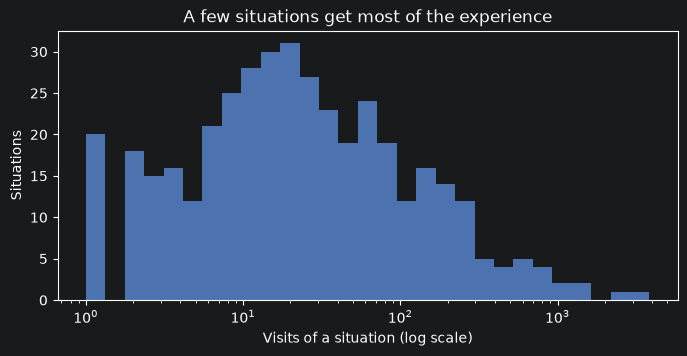

{
  "return": 23.051447663417385,
  "crash": 0.08,
  "speed": 23.048655246256267,
  "distance": 673.7452053591084,
  "length": 29.24
}


In [9]:
# --- HOW THE TABLE WAS USED ---

# Visits per situation (summed over the actions).
visits_per_state = visits.sum(axis=-1).ravel()

# Situations visited at least once.
print(f"Situations visited at least once: {(visits_per_state > 0).sum()} of {N_STATES}")

# Situations visited at least 100 times.
print(f"Situations visited at least 100 times: {(visits_per_state >= 100).sum()}")

# Share of all updates that went to the 20 most visited situations.
print(f"Share of all updates in the 20 most visited situations: {np.sort(visits_per_state)[-20:].sum() / visits_per_state.sum():.0%}")

# Histogram of visits (log scale), only visited situations.
plt.figure(figsize=(8, 3.5))

# Log-spaced bins.
plt.hist(visits_per_state[visits_per_state > 0], bins=np.logspace(0, np.log10(visits_per_state.max() + 1), 30), color="#4C72B0")

# Logarithmic x axis.
plt.xscale("log")

# Labels.
plt.xlabel("Visits of a situation (log scale)")

# y-axis label.
plt.ylabel("Situations")

# Title.
plt.title("A few situations get most of the experience")

# Render.
plt.show()

# --- SAVE THE RESULTS ---

# Means of the learned driver.
results_all["v2 Q-learning"] = {metric: float(values.mean()) for metric, values in res_q.items()}

# Write the file.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show the v2 entry.
print(json.dumps(results_all["v2 Q-learning"], indent=2))

## Results and conclusions

### Summary on the 50 test scenarios
| Driver | Return | Crash rate | Mean speed | Distance | Seconds survived |
|---|---|---|---|---|---|
| v1 random | 8.6–9.2 | 98% | 24.4 m/s | ~290 m | ~12 |
| v1 always `IDLE` | 12.86 | 92% | 24.3 m/s | 402 m | 16.2 |
| v1 rule-based | 22.83 | **2%** | 22.5 m/s | 670 m | 29.7 |
| **v2 Q-learning** | **23.05** | 8% | **23.0 m/s** | **674 m** | 29.2 |

*(The random driver is not exactly reproducible: highway-env re-creates its action space at every reset, which discards the seed. That is why its value differs slightly between runs.)*

**Q-learning matches the hand-written driver** in return (23.05 against 22.83), learning only from the reward. It gets there with a different trade-off: it drives slightly faster (23.0 against 22.5 m/s), but crashes 4 times out of 50 instead of once. The difference in return is small; the difference in safety is not, so the rule-based driver is still the better driver.

### Training
- 2,000 episodes in about 8.5 minutes (0.25 s per episode).
- **The first 600 episodes look like a random driver** (return about 9, crash rate about 95%): with $\varepsilon$ close to 1 the agent explores almost at random, but the table is already being filled.
- **The return then rises steadily as $\varepsilon$ decreases**, up to about 20 (moving average) at the end, and the crash rate drops from about 95% to about 30%.
- **Why 30% crashes during training but 8% in the test?** At the end of training $\varepsilon = 0.05$ is still active: about 1.5 random actions per 30-second episode, and on a busy highway one random lane change or acceleration is often enough to crash. The test uses the greedy policy, with no random actions.

### What the table learned
The heatmap (middle lane, medium speed) is mostly sensible:
- **close car ahead, left lane free → `LANE_LEFT`**; left lane blocked, right free → `LANE_RIGHT`: the agent overtakes on the free side;
- **both side lanes blocked (close cars) → `SLOWER`**: when there is no way out, it brakes;
- with a medium gap it often changes lane early, rather than waiting to get close.

But it also shows the weaknesses of a table:
- **close car ahead with cars beside on both sides → `FASTER`**, a recipe for a crash; and **free road with cars beside on both sides → `LANE_LEFT`**, into a car. These situations are rare, so they were updated only a few times: their values still contain much of the **optimistic initial value** ($Q = 10$), and an action that was never tried can look like the best one;
- **close car ahead with both side lanes free → `SLOWER`** instead of overtaking: safe but slow, which matches the low share of `FASTER` (11%) and the high share of `SLOWER` (32%) on the test scenarios.

### How the experience was spread
- Only **406 of the 972 situations** were ever visited (42%), and only **77 were visited at least 100 times**.
- **52% of all updates went to the 20 most visited situations**: open road, light traffic. The dangerous situations, where the right decision matters most, are exactly the rare ones.
- This is the core limit of tabular methods: each situation is learned **separately**, so a rare situation stays almost untrained even if it is very similar to a common one.

### Next step
**v3, Deep Q-Network (DQN):** a neural network $Q_\theta(s, a)$ replaces the table. It reads the full observation (10 vehicles, continuous values, no hand-made buckets) and **generalises**: what it learns about a car 19 m ahead also applies to one 21 m ahead, and the rare dangerous situations benefit from the common ones.